In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv



# K-Nearest Neighbors (KNN) Classification

## 1. Introduction

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm used for classification and regression.

It predicts the output of a new observation by examining the K closest observations in the training dataset.

### How does KNN work?

1. Choose the value of K.
2. Calculate the distance between the new observation and the training observations.
3. Identify the K nearest neighbors.
4. For classification, count the classes among those neighbors.
5. Assign the majority class to the new observation.

For regression, KNN generally predicts the average or weighted average of the neighbors' target values.

### Objective

Build a KNN classification model to predict whether a tumor is benign or malignant using numerical measurements.

### Algorithm

K-Nearest Neighbors Classifier (`KNeighborsClassifier`).

### Dataset

Breast Cancer Wisconsin (Diagnostic) dataset from Kaggle.



## 2. When to Use and When Not to Use KNN

### When should we use KNN?

1. When the dataset is small or moderately sized.
2. When similar observations are expected to have similar target labels.
3. When the relationship between features and the target is nonlinear.
4. When a simple, non-parametric baseline model is required.
5. When the dataset contains meaningful numerical features and an appropriate distance metric can be chosen.

### When should we avoid or be cautious with KNN?

1. Very large datasets: prediction can be slow because distances to training observations must be calculated.
2. High-dimensional datasets: distances may become less informative as the number of features increases.
3. Features with different scales: large-scale features can dominate distance calculations.
4. Noisy datasets: irrelevant features and outliers can mislead neighbors.
5. Imbalanced datasets: the majority class can dominate the neighborhood.
6. Datasets with many missing values: missing values must be handled before calculating distances.

### Advantages

- Simple to understand and implement.
- No explicit model-fitting equation is required.
- Can capture nonlinear decision boundaries.
- Supports classification and regression.

### Disadvantages

- Prediction can be computationally expensive.
- Requires appropriate feature scaling.
- Choosing K and the distance metric affects performance.
- Can consume substantial memory because training observations must be retained.

### Important Concept

KNN is called a lazy learner because it stores the training data rather than learning a compact parametric model during training.



## 3. Mathematical Foundation of KNN

KNN uses a distance metric to measure how close two observations are.

### Euclidean Distance

The most commonly used distance metric for numerical features is Euclidean distance.

For two observations X and Y with n features:

d(X, Y) = sqrt(Σ (Xi - Yi)²)

Where:

- X and Y are two observations.
- Xi and Yi are their values for feature i.
- n is the number of features.
- d(X, Y) is the distance between them.

### Example

Suppose two observations are:

X = (2, 3)
Y = (5, 7)

Distance = sqrt((5 - 2)² + (7 - 3)²)

Distance = sqrt(9 + 16)

Distance = 5

A smaller distance indicates that the observations are closer.

### What happens when K changes?

- K = 1: The closest single neighbor determines the prediction.
- Small K: More sensitive to noise and individual observations.
- Large K: Smoother decisions, but may underfit.
- Best K: Must be selected using validation data or cross-validation.

For binary classification, an odd K can sometimes reduce tied votes, but an odd value does not guarantee that ties are impossible in every multiclass problem.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import(
train_test_split,GridSearchCV,StratifiedKFold
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [7]:
df = pd.read_csv(
    '/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv'
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [8]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDiagnosis distribution:")
print(df["diagnosis"].value_counts())

Dataset shape: (569, 33)

Column names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non

In [9]:
df = df.drop(columns=["id"], errors="ignore")

df = df.loc[
    :,
    ~df.columns.str.contains("^Unnamed")
]

df = df.drop_duplicates().copy()

print("Cleaned dataset shape:", df.shape)

display(df.head())

Cleaned dataset shape: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


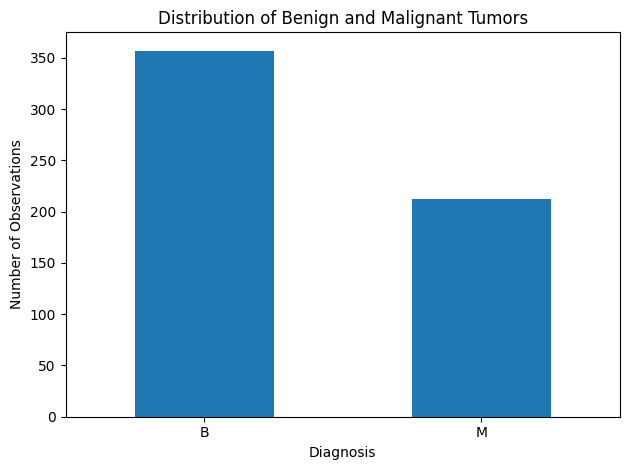

In [10]:
df["diagnosis"].value_counts().plot(
    kind="bar",
    xlabel="Diagnosis",
    ylabel="Number of Observations",
    title="Distribution of Benign and Malignant Tumors"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.unique())

Features shape: (569, 30)
Target shape: (569,)

Target classes:
['M' 'B']


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [14]:
knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski",
        p=2
    ))
])

knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [15]:
y_pred = knn_model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

display(results.head(10))

,Actual,Predicted
0,B,B
1,M,M
2,B,B
3,M,B
4,B,B
5,B,B
6,M,M
7,B,B
8,B,B
9,B,B


In [16]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

print(
    f"Precision (malignant): "
    f"{precision_score(y_test, y_pred, pos_label='M'):.4f}"
)

print(
    f"Recall (malignant): "
    f"{recall_score(y_test, y_pred, pos_label='M'):.4f}"
)

print(
    f"F1-score (malignant): "
    f"{f1_score(y_test, y_pred, pos_label='M'):.4f}"
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9561
Precision (malignant): 0.9744
Recall (malignant): 0.9048
F1-score (malignant): 0.9383

Classification Report:
              precision    recall  f1-score   support

           B       0.95      0.99      0.97        72
           M       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



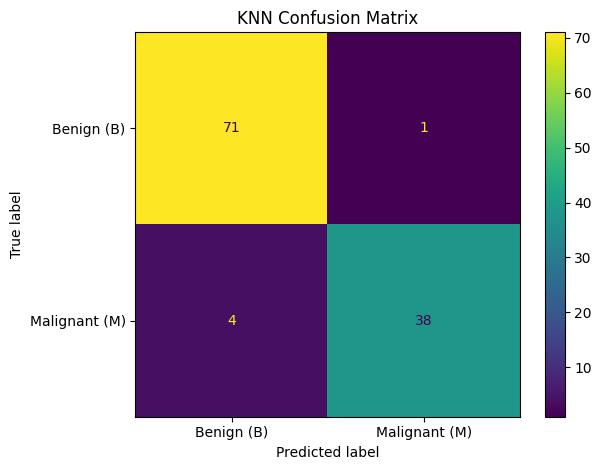

In [17]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["B", "M"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign (B)", "Malignant (M)"]
)

disp.plot()
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid = {
    "knn__n_neighbors": list(range(1, 26, 2))
}

grid_search = GridSearchCV(
    estimator=knn_model,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best K:", grid_search.best_params_["knn__n_neighbors"])
print("Best cross-validation accuracy:", round(grid_search.best_score_, 4))

Best K: 3
Best cross-validation accuracy: 0.9736


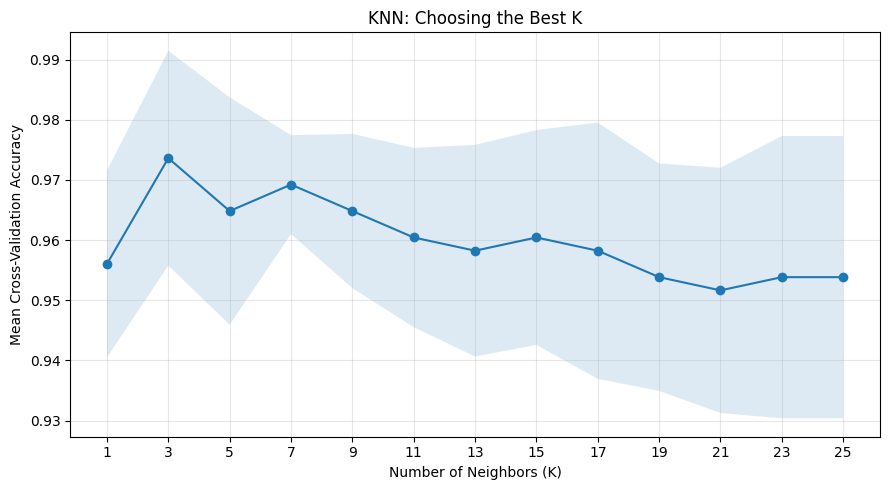

In [19]:
cv_results = pd.DataFrame(grid_search.cv_results_)

k_values = cv_results["param_knn__n_neighbors"].astype(int)
mean_scores = cv_results["mean_test_score"]
std_scores = cv_results["std_test_score"]

plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    mean_scores,
    marker="o"
)

plt.fill_between(
    k_values,
    mean_scores - std_scores,
    mean_scores + std_scores,
    alpha=0.15
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("KNN: Choosing the Best K")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Best K: 3
Test accuracy: 0.9386

Classification Report:
              precision    recall  f1-score   support

           B       0.92      0.99      0.95        72
           M       0.97      0.86      0.91        42

    accuracy                           0.94       114
   macro avg       0.95      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



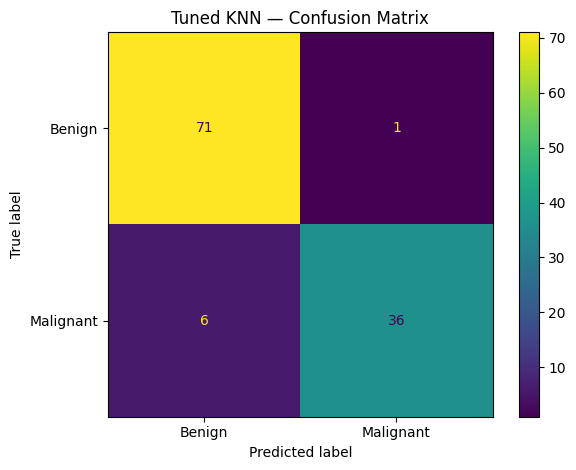

In [20]:
best_knn = grid_search.best_estimator_

y_pred_best = best_knn.predict(X_test)

print("Best K:", grid_search.best_params_["knn__n_neighbors"])

print(
    f"Test accuracy: "
    f"{accuracy_score(y_test, y_pred_best):.4f}"
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    labels=["B", "M"],
    display_labels=["Benign", "Malignant"]
)

plt.title("Tuned KNN — Confusion Matrix")
plt.tight_layout()
plt.show()

In [21]:
# Select one observation from the test set
new_sample = X_test.iloc[[0]]

prediction = best_knn.predict(new_sample)
probabilities = best_knn.predict_proba(new_sample)

print("Predicted diagnosis:", prediction[0])
print("Actual diagnosis:", y_test.iloc[0])

print(
    "Estimated class probabilities:",
    dict(zip(
        best_knn.classes_,
        probabilities[0].round(4)
    ))
)

Predicted diagnosis: B
Actual diagnosis: B
Estimated class probabilities: {'B': np.float64(1.0), 'M': np.float64(0.0)}
